# Experimental Validation of an AI Model for Biomaterial Performance

## Project question
Can hydrogel formulation and specimen geometry predict apparent compressive modulus, and how well do those predictions agree with held-out experimental formulations?

This notebook processes the local raw rheometer files, engineers one row per specimen, trains a Ridge regression model, compares it with a mean baseline, and saves evaluation results. The validation is retrospective and grouped by formulation; it is not prospective validation on newly fabricated specimens.

## Target and paper alignment
The target `adapted_modulus_target_kPa` is the loading-branch slope of stress versus compression strain from 2% to 10%. It is an accessible, paper-inspired stiffness estimate. The attached Heidenreich et al. paper instead identifies modified one-term Ogden parameters using finite-element inverse fitting over compression and tension data and derives apparent Young's modulus as approximately `3 * mu` for near-incompressible hydrogels. This notebook does **not** reproduce that finite-element inverse analysis.

## Literature and data sources
- Heidenreich, S. J. et al. (2026). “Deciphering melanoma brain metastases: Role of cellular plasticity and metastatic origin.” *Biomaterials Advances*, 188, 214983. DOI: [10.1016/j.bioadv.2026.214983](https://doi.org/10.1016/j.bioadv.2026.214983).
- Faber et al. Experimental hydrogel curves, Zenodo record [10.5281/zenodo.18171138](https://doi.org/10.5281/zenodo.18171138), CC BY 4.0. Cite/attribute the data creators when reusing the source dataset.

## Important modeling rule
Force, torque, gap, stress, and curve-derived modulus summaries describe the same measured response. They are retained for quality control, but **must not be predictors** when the target is calculated from that same curve. The model below uses only formulation descriptors and geometry.


# Project files

Open the interactive project dashboard: [Biomaterial Performance Dashboard](biomaterial-project-dashboard.html).

This notebook contains the data processing, exploratory analysis, model training, and evaluation workflow. The dashboard presents the project results and specimen-level summaries.

## 1. Setup

Install dependencies once in the active Python environment if needed: `python -m pip install -r requirements.txt`. Then set the data folder below to the folder containing the raw `.txt` traces and matching `*_geom.yaml` files.

In [1]:
from pathlib import Path
import math
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_ROOT = Path(
    "/Users/jay/Desktop/MTech AI in Healthcare/Biomaterial/project/"
    "data_OHA-GEL_ADA-GEL_Alg"
)
OUTPUT_DIR = Path.cwd() / "notebook_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RAW_COLUMNS = [
    "Time (s)", "Encoder (rad)", "Torque (Nm)",
    "Marker", "Normal force (N)", "Gap (um)",
]

print("Data folder exists:", DATA_ROOT.exists())
print("Output folder:", OUTPUT_DIR.resolve())


/opt/anaconda3/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


Data folder exists: True
Output folder: /Users/jay/Documents/Codex/2026-10-19/referenced-chatgpt-conversation-this-is-an-2/outputs/project_package/notebook_outputs


## 2. Find and inspect the raw experiments

Each input file should contain the six named measurement columns. The raw files may have a trailing tab, so the loader reads only the first six columns. A displayed pandas row index is not a measurement column.

In [3]:
raw_files = sorted(p for p in DATA_ROOT.rglob("*.txt") if p.is_file())
if not raw_files:
    raise FileNotFoundError(f"No .txt files found under {DATA_ROOT}")

print("Raw text files found:", len(raw_files))
first = pd.read_csv(raw_files[0], sep="\t", index_col=False, usecols=range(6), nrows=5)
first.columns = RAW_COLUMNS
display(first)


Raw text files found: 36


,Time (s),Encoder (rad),Torque (Nm),Marker,Normal force (N),Gap (um)
0,0.000000,0.000000e+00,0.000008,0,0.000107,4037.964844
1,0.002080,-9.881093e-07,0.000006,0,0.003048,4037.964844
2,0.006176,1.655474e-06,-0.000005,0,0.000618,4037.964844
3,0.010272,1.433019e-06,0.000001,0,0.000454,4037.964844
4,0.014368,-5.880014e-07,0.000003,0,0.003098,4037.964844


## 3. Feature engineering per specimen

Inputs to the model are formulation/geometry features. Signal summaries below are useful for quality checks and exploratory analysis. The target modulus is calculated from the measured force and gap curve; it is intentionally kept separate from the predictor matrix.

In [4]:
def parse_pct(token):
    return float(token.replace("p", "."))


def get_formulation(path):
    text = path.stem + " " + path.parent.name
    lower = text.lower()
    material = (
        "OHA_GEL" if "oha" in lower else
        "ADA_GEL" if "ada" in lower else
        "alginate" if "alg" in lower else "unknown"
    )
    alginate_pct = oha_pct = ada_pct = primary_polymer_pct = np.nan
    gelatin_pct = np.nan
    crosslinker = "unknown"

    m = re.search(r"GEL[-_](\d+p\d+)[-_](\d+p\d+)", text, re.I)
    if m and material == "OHA_GEL":
        oha_pct, gelatin_pct = map(parse_pct, m.groups())
        primary_polymer_pct = oha_pct

    if material == "alginate":
        m = re.search(r"(\d+p\d+)[-_]Alg", text, re.I)
        if not m:
            m = re.search(r"(\d+p\d+)_Alg", path.parent.name, re.I)
        if m:
            alginate_pct = primary_polymer_pct = parse_pct(m.group(1))
        gelatin_pct = 0.0
        crosslinker = "CaCl2"
    elif material == "ADA_GEL":
        m = re.search(r"ADA[-_]?Gel[-_]?(\d+p\d+)", text, re.I)
        if not m:
            m = re.search(r"(\d+p\d+)_ADA", path.parent.name, re.I)
        if m:
            ada_pct = primary_polymer_pct = parse_pct(m.group(1))
        # The filename does not specify the ADA-GEL component ratio.
        crosslinker = "CaCl2"
    elif material == "OHA_GEL":
        crosslinker = "mTG" if "mtg" in lower else "unknown"

    return {
        "formulation_id": path.parent.name,
        "material_type": material,
        "alginate_pct_wv": alginate_pct,
        "oha_pct_wv": oha_pct,
        "ada_pct_wv": ada_pct,
        "primary_polymer_pct_wv": primary_polymer_pct,
        "gelatin_pct_wv": gelatin_pct,
        "crosslinker": crosslinker,
    }


def get_radius_m(path):
    sidecar = path.with_name(path.stem + "_geom.yaml")
    if not sidecar.exists():
        return np.nan
    yaml_text = sidecar.read_text(errors="replace")
    m = re.search(r"^\s*radius\s*:\s*([-+0-9.eE]+)", yaml_text, re.M)
    if m:
        return float(m.group(1))  # provided geometry files use metres
    m = re.search(r"^\s*diameter\s*:\s*([-+0-9.eE]+)", yaml_text, re.M)
    return float(m.group(1)) / 2 if m else np.nan


def extract_one(path):
    df = pd.read_csv(path, sep="\t", index_col=False, usecols=range(6))
    if list(df.columns) != RAW_COLUMNS:
        raise ValueError(f"Unexpected columns in {path.name}: {df.columns.tolist()}")
    df = df.apply(pd.to_numeric, errors="coerce").dropna().reset_index(drop=True)
    if len(df) < 10:
        raise ValueError(f"Too few valid rows in {path.name}")

    t = df["Time (s)"].to_numpy(float)
    encoder = df["Encoder (rad)"].to_numpy(float)
    torque = df["Torque (Nm)"].to_numpy(float)
    marker = df["Marker"].to_numpy(float)
    force = df["Normal force (N)"].to_numpy(float)
    gap = df["Gap (um)"].to_numpy(float)

    radius_m = get_radius_m(path)
    area_m2 = math.pi * radius_m**2 if np.isfinite(radius_m) and radius_m > 0 else np.nan
    n0 = min(100, len(df))
    h0_um = float(np.median(gap[:n0]))
    f0_n = float(np.median(force[:n0]))
    strain = (h0_um - gap) / h0_um
    stress_kpa = np.abs(force - f0_n) / area_m2 / 1000 if np.isfinite(area_m2) else np.full_like(force, np.nan)

    increasing_time = np.all(np.diff(t) > 0)
    strain_rate = np.gradient(strain, t) if increasing_time else np.full_like(strain, np.nan)
    velocity = np.gradient(encoder, t) if increasing_time else np.full_like(encoder, np.nan)
    loading = np.isfinite(strain_rate) & (strain_rate > 0)
    fit_mask = loading & (strain >= 0.02) & (strain <= 0.10) & np.isfinite(stress_kpa)
    modulus = float(np.polyfit(strain[fit_mask], stress_kpa[fit_mask], 1)[0]) if fit_mask.sum() >= 10 else np.nan

    row = {
        "source_file": path.name,
        "n_rows": len(df),
        **get_formulation(path),
        "radius_mm": radius_m * 1000 if np.isfinite(radius_m) else np.nan,
        "area_mm2": area_m2 * 1e6 if np.isfinite(area_m2) else np.nan,
        "duration_s": float(t[-1] - t[0]),
        "sampling_interval_mean_s": float(np.mean(np.diff(t))),
        "encoder_range_rad": float(np.ptp(encoder)),
        "encoder_velocity_rms_rad_s": float(np.sqrt(np.mean(velocity**2))),
        "torque_mean_Nm": float(np.mean(torque)),
        "torque_sd_Nm": float(np.std(torque)),
        "torque_abs_max_Nm": float(np.max(np.abs(torque))),
        "normal_force_mean_N": float(np.mean(force)),
        "normal_force_sd_N": float(np.std(force)),
        "normal_force_min_N": float(np.min(force)),
        "normal_force_max_N": float(np.max(force)),
        "normal_force_p95_N": float(np.percentile(force, 95)),
        "normal_force_rms_N": float(np.sqrt(np.mean(force**2))),
        "gap_initial_um": h0_um,
        "gap_min_um": float(np.min(gap)),
        "gap_max_um": float(np.max(gap)),
        "gap_range_um": float(np.ptp(gap)),
        "gap_sd_um": float(np.std(gap)),
        "max_compression_strain": float(np.max(strain)),
        "max_tension_strain_abs": float(abs(np.min(strain))),
        "stress_max_kPa": float(np.nanmax(stress_kpa)),
        "stress_min_kPa": float(np.nanmin(stress_kpa)),
        "stress_p95_kPa": float(np.nanpercentile(stress_kpa, 95)),
        "marker_count": int(np.count_nonzero(marker == 1)),
        "marker_fraction": float(np.mean(marker == 1)),
        "adapted_modulus_target_kPa": modulus,
    }
    return row


rows = []
errors = []
for file in raw_files:
    try:
        rows.append(extract_one(file))
    except Exception as exc:
        errors.append((file.name, str(exc)))

specimens = pd.DataFrame(rows)
print(f"Successfully processed: {len(specimens)} / {len(raw_files)}")
if errors:
    print("Skipped files:")
    display(pd.DataFrame(errors, columns=["file", "reason"]))
if specimens.empty:
    raise RuntimeError("No usable raw files were processed.")
display(specimens[["source_file", "material_type", "primary_polymer_pct_wv",
                   "gelatin_pct_wv", "radius_mm", "adapted_modulus_target_kPa"]].head())


Successfully processed: 36 / 36


,source_file,material_type,primary_polymer_pct_wv,gelatin_pct_wv,radius_mm,adapted_modulus_target_kPa
0,OHA-GEL_R_20231017_ML_B1-S1-P2a-OHA-40-GEL-3p7...,OHA_GEL,3.75,3.75,4.0,5.882482
1,OHA-GEL_R_20231017_ML_B1-S2-P2a-OHA-40-GEL-3p7...,OHA_GEL,3.75,3.75,4.0,5.518562
2,OHA-GEL_R_20231017_ML_B1-S3-P2a-OHA-40-GEL-3p7...,OHA_GEL,3.75,3.75,4.0,6.237849
3,OHA-GEL_R_20231017_ML_B1-S4-P2a-OHA-40-GEL-3p7...,OHA_GEL,3.75,3.75,4.0,7.946616
4,OHA-GEL_R_20231017_ML_B1-S5-P2a-OHA-40-GEL-3p7...,OHA_GEL,3.75,3.75,4.0,8.110356


## 4. Inspect data quality and specimen-level targets

The file-level target is the adapted 2–10% compression loading slope. Geometry is required to convert force to stress. Missing composition fields mean the filename did not specify that component; they are not zero measurements.

In [5]:
quality = pd.DataFrame({
    "quantity": ["specimens", "formulations", "missing geometry", "missing modulus target"],
    "value": [len(specimens), specimens.formulation_id.nunique(),
              int(specimens.radius_mm.isna().sum()),
              int(specimens.adapted_modulus_target_kPa.isna().sum())],
})
display(quality)
display(specimens.groupby(["material_type", "formulation_id"], dropna=False)
        .agg(n_specimens=("source_file", "count"),
             modulus_mean_kPa=("adapted_modulus_target_kPa", "mean"),
             modulus_sd_kPa=("adapted_modulus_target_kPa", "std"))
        .reset_index())


,quantity,value
0,specimens,36
1,formulations,7
2,missing geometry,0
3,missing modulus target,0


,material_type,formulation_id,n_specimens,modulus_mean_kPa,modulus_sd_kPa
0,ADA_GEL,20240527_0603_0p6_ADA-GEL_PH163_DO_13_HBSS,5,5.856452,2.843226
1,OHA_GEL,20231017_OHA_40_00_GEL_3p75-3p75_15mTG_4h_D0,6,7.005334,1.260036
2,OHA_GEL,20240903_20250903_OHA_40_00_GEL_1p25-3p75_15mT...,6,5.167268,1.204311
3,OHA_GEL,20250805_20251105_OHA_40_00_GEL_3p75-2p5_15mTG...,4,2.010199,0.609694
4,alginate,20240410_0p3_Alg_HBSS,5,4.527423,2.923440
5,alginate,20240415_0p6_Alg_HBSS,5,4.708384,1.486536
6,alginate,20240422_1p2_Alg_HBSS,5,9.230731,1.324998


## 5. Exploratory data analysis (EDA)

Use these summaries and plots to understand replicate variability, formulation coverage, missing metadata, the measured stiffness distribution, and the shape/range of a representative rheometer curve. EDA informs feature selection and data-quality decisions; it does not replace held-out validation.


In [6]:
# Coverage and missingness
print(f"Specimens: {len(specimens)} | Formulations: {specimens.formulation_id.nunique()} | Materials: {specimens.material_type.nunique()}")
missing = specimens.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].rename("missing_count").to_frame())

summary_columns = [
    "adapted_modulus_target_kPa", "radius_mm", "duration_s",
    "max_compression_strain", "max_tension_strain_abs",
    "normal_force_max_N", "stress_max_kPa", "gap_range_um",
]
display(specimens[summary_columns].describe().T.round(3))

formulation_summary = (
    specimens.groupby(["material_type", "formulation_id"], dropna=False)
    .agg(n=("source_file", "count"),
         modulus_mean_kPa=("adapted_modulus_target_kPa", "mean"),
         modulus_sd_kPa=("adapted_modulus_target_kPa", "std"),
         polymer_pct=("primary_polymer_pct_wv", "first"),
         gelatin_pct=("gelatin_pct_wv", "first"))
    .reset_index()
)
display(formulation_summary.round(3))


Specimens: 36 | Formulations: 7 | Materials: 3


,missing_count
ada_pct_wv,31
alginate_pct_wv,21
oha_pct_wv,20
gelatin_pct_wv,5


,count,mean,std,min,25%,50%,75%,max
adapted_modulus_target_kPa,36.0,5.630,2.614,1.239,3.685,5.606,7.425,10.803
radius_mm,36.0,3.798,0.284,3.047,3.566,4.000,4.000,4.122
duration_s,36.0,1079.069,56.717,978.829,1024.952,1090.460,1126.229,1163.639
max_compression_strain,36.0,0.150,0.000,0.149,0.150,0.150,0.150,0.150
max_tension_strain_abs,36.0,0.150,0.000,0.150,0.150,0.150,0.150,0.151
normal_force_max_N,36.0,0.063,0.026,0.026,0.039,0.064,0.084,0.119
stress_max_kPa,36.0,1.326,0.540,0.581,0.816,1.230,1.641,2.625
gap_range_um,36.0,997.723,324.371,414.656,737.720,1093.387,1249.729,1407.902


,material_type,formulation_id,n,modulus_mean_kPa,modulus_sd_kPa,polymer_pct,gelatin_pct
0,ADA_GEL,20240527_0603_0p6_ADA-GEL_PH163_DO_13_HBSS,5,5.856,2.843,0.60,NaN
1,OHA_GEL,20231017_OHA_40_00_GEL_3p75-3p75_15mTG_4h_D0,6,7.005,1.260,3.75,3.75
2,OHA_GEL,20240903_20250903_OHA_40_00_GEL_1p25-3p75_15mT...,6,5.167,1.204,1.25,3.75
3,OHA_GEL,20250805_20251105_OHA_40_00_GEL_3p75-2p5_15mTG...,4,2.010,0.610,1.25,3.75
4,alginate,20240410_0p3_Alg_HBSS,5,4.527,2.923,0.30,0.00
5,alginate,20240415_0p6_Alg_HBSS,5,4.708,1.487,0.60,0.00
6,alginate,20240422_1p2_Alg_HBSS,5,9.231,1.325,1.20,0.00


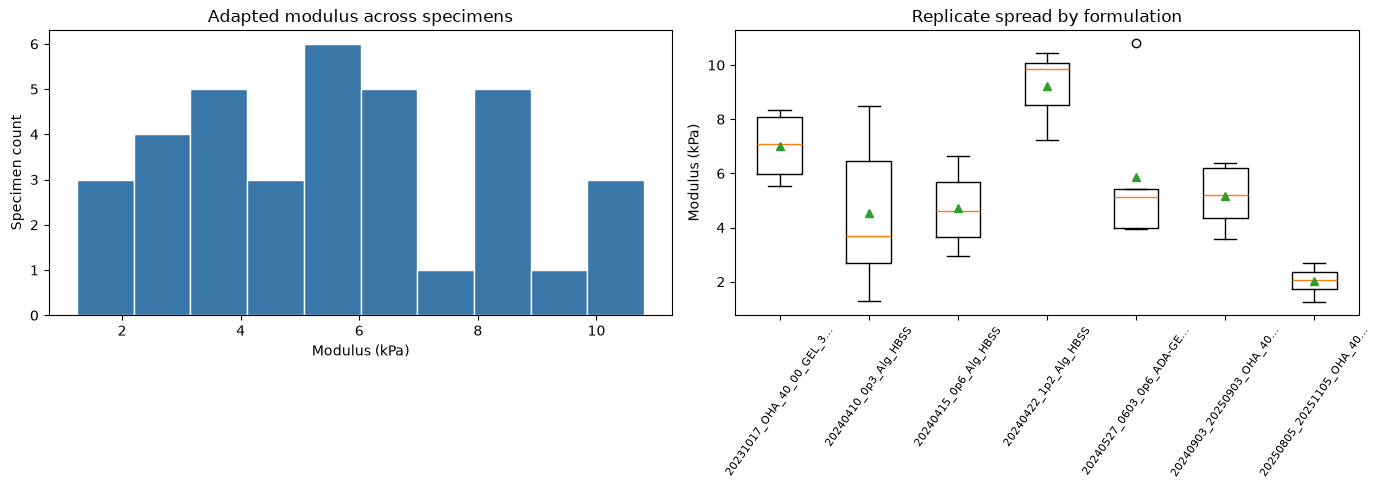

In [7]:
# Target distribution and formulation-level replicate spread
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(specimens["adapted_modulus_target_kPa"].dropna(), bins=10,
             color="#3977a8", edgecolor="white")
axes[0].set(title="Adapted modulus across specimens", xlabel="Modulus (kPa)", ylabel="Specimen count")

groups_for_plot = [g["adapted_modulus_target_kPa"].dropna().to_numpy()
                   for _, g in specimens.groupby("formulation_id", sort=True)]
labels_for_plot = [name for name, _ in sorted(specimens.groupby("formulation_id", sort=True))]
short_labels = [label[:24] + "…" if len(label) > 24 else label for label in labels_for_plot]
axes[1].boxplot(groups_for_plot, showmeans=True)
axes[1].set_xticks(range(1, len(short_labels) + 1))
axes[1].set_xticklabels(short_labels)
axes[1].set(title="Replicate spread by formulation", ylabel="Modulus (kPa)")
axes[1].tick_params(axis="x", labelrotation=55, labelsize=8)
fig.tight_layout()
plt.show()


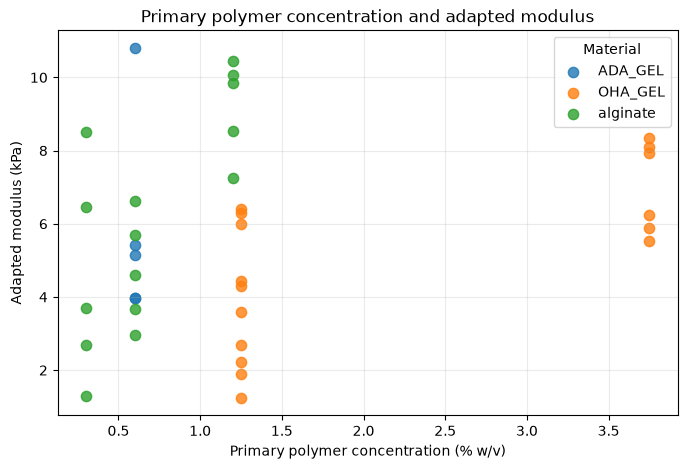

In [8]:
# Formulation composition versus measured modulus
fig, ax = plt.subplots(figsize=(8, 5))
for material, part in specimens.groupby("material_type"):
    ax.scatter(part["primary_polymer_pct_wv"], part["adapted_modulus_target_kPa"],
               label=material, alpha=0.8, s=55)
ax.set(title="Primary polymer concentration and adapted modulus",
       xlabel="Primary polymer concentration (% w/v)", ylabel="Adapted modulus (kPa)")
ax.legend(title="Material")
ax.grid(alpha=0.25)
plt.show()


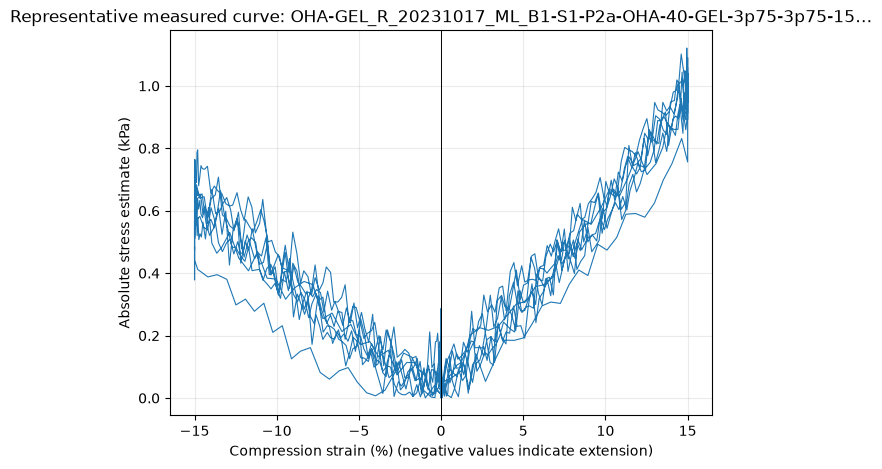

In [9]:
# Plot a representative stress–strain trace, downsampled for display only
sample_path = raw_files[0]
curve = pd.read_csv(sample_path, sep="\t", index_col=False, usecols=range(6))
curve.columns = RAW_COLUMNS
for col in RAW_COLUMNS:
    curve[col] = pd.to_numeric(curve[col], errors="coerce")
curve = curve.dropna(subset=RAW_COLUMNS)
radius_m = get_radius_m(sample_path)
if not np.isfinite(radius_m):
    print("No geometry radius for representative curve; skipping stress conversion.")
else:
    h0 = float(curve["Gap (um)"].iloc[:100].median())
    f0 = float(curve["Normal force (N)"].iloc[:100].median())
    area_m2 = math.pi * radius_m**2
    curve_strain = (h0 - curve["Gap (um)"].to_numpy()) / h0
    curve_stress = np.abs(curve["Normal force (N)"].to_numpy() - f0) / area_m2 / 1000
    step = max(1, len(curve) // 5000)
    plt.figure(figsize=(7, 5))
    plt.plot(curve_strain[::step] * 100, curve_stress[::step], lw=0.8)
    plt.axvline(0, color="black", lw=0.7)
    plt.xlabel("Compression strain (%) (negative values indicate extension)")
    plt.ylabel("Absolute stress estimate (kPa)")
    plt.title(f"Representative measured curve: {sample_path.name[:55]}…")
    plt.grid(alpha=0.25)
    plt.show()


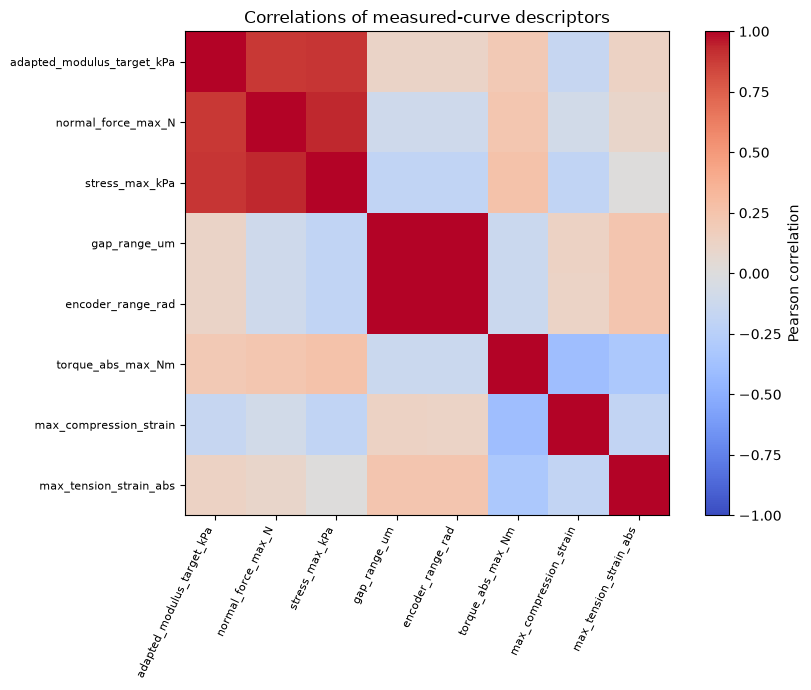

In [10]:
# Correlations among selected curve descriptors (exploratory only)
curve_descriptors = [
    "adapted_modulus_target_kPa", "normal_force_max_N", "stress_max_kPa",
    "gap_range_um", "encoder_range_rad", "torque_abs_max_Nm",
    "max_compression_strain", "max_tension_strain_abs",
]
corr = specimens[curve_descriptors].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=65, ha="right", fontsize=8)
ax.set_yticks(range(len(corr.index)), corr.index, fontsize=8)
ax.set_title("Correlations of measured-curve descriptors")
fig.colorbar(image, ax=ax, label="Pearson correlation")
fig.tight_layout()
plt.show()


## 6. Prepare formulation-level predictors

The predictors are material class, reported formulation concentrations, crosslinker, and specimen radius. Curve-derived summaries are excluded to prevent target leakage. The formulation ID is used only to group folds, not as a predictive feature.

In [11]:
target = "adapted_modulus_target_kPa"
model_data = specimens.dropna(subset=[target, "formulation_id", "radius_mm"]).copy()
numeric_features = [
    "alginate_pct_wv", "oha_pct_wv", "ada_pct_wv", "primary_polymer_pct_wv",
    "gelatin_pct_wv", "radius_mm",
]
categorical_features = ["material_type", "crosslinker"]

# Missing composition values are accompanied by indicators so unknown values
# are distinguishable from measured zero concentrations.
X = model_data[numeric_features].copy()
for col in numeric_features:
    X[col + "_missing"] = X[col].isna().astype(float)
X[numeric_features] = X[numeric_features].fillna(0.0)
X_cat = pd.get_dummies(model_data[categorical_features].fillna("unknown"), dtype=float)
X = pd.concat([X.reset_index(drop=True), X_cat.reset_index(drop=True)], axis=1)
y = model_data[target].to_numpy(float)
groups = model_data["formulation_id"].to_numpy()

print("Specimens available:", len(model_data))
print("Unique formulations:", model_data.formulation_id.nunique())
print("Model input features:", list(X.columns))


Specimens available: 36
Unique formulations: 7
Model input features: ['alginate_pct_wv', 'oha_pct_wv', 'ada_pct_wv', 'primary_polymer_pct_wv', 'gelatin_pct_wv', 'radius_mm', 'alginate_pct_wv_missing', 'oha_pct_wv_missing', 'ada_pct_wv_missing', 'primary_polymer_pct_wv_missing', 'gelatin_pct_wv_missing', 'radius_mm_missing', 'material_type_ADA_GEL', 'material_type_OHA_GEL', 'material_type_alginate', 'crosslinker_CaCl2', 'crosslinker_mTG']


## 7. Train and evaluate with leave-one-formulation-out validation

Each fold holds out every specimen from one formulation. This reduces leakage between replicates. With only a few formulations, results are exploratory. Ridge uses a fixed regularization strength (`alpha=1`); no hyperparameter tuning is performed on this small dataset.

In [12]:
def fit_ridge(x_train, y_train, alpha=1.0):
    mean = x_train.mean(axis=0)
    scale = x_train.std(axis=0)
    scale[scale == 0] = 1.0
    z = (x_train - mean) / scale
    design = np.column_stack([np.ones(len(z)), z])
    penalty = np.eye(design.shape[1]) * alpha
    penalty[0, 0] = 0.0  # do not penalize intercept
    coef = np.linalg.solve(design.T @ design + penalty, design.T @ y_train)
    return mean, scale, coef


def predict_ridge(x, state):
    mean, scale, coef = state
    z = (x - mean) / scale
    return np.column_stack([np.ones(len(z)), z]) @ coef


def calculate_metrics(actual, predicted):
    error = actual - predicted
    denom = np.sum((actual - actual.mean()) ** 2)
    return {
        "MAE_kPa": float(np.mean(np.abs(error))),
        "RMSE_kPa": float(np.sqrt(np.mean(error**2))),
        "R2": float(1 - np.sum(error**2) / denom) if denom > 0 else np.nan,
    }


x_values = X.to_numpy(float)
oof_model = np.full(len(y), np.nan)
oof_baseline = np.full(len(y), np.nan)
fold_labels = np.empty(len(y), dtype=object)

for formulation in np.unique(groups):
    test = groups == formulation
    train = ~test
    if train.sum() < 2:
        continue
    state = fit_ridge(x_values[train], y[train], alpha=1.0)
    oof_model[test] = predict_ridge(x_values[test], state)
    oof_baseline[test] = float(np.mean(y[train]))
    fold_labels[test] = formulation

valid = np.isfinite(oof_model) & np.isfinite(oof_baseline)
metrics = pd.DataFrame([
    {"model": "mean_baseline", **calculate_metrics(y[valid], oof_baseline[valid])},
    {"model": "ridge", **calculate_metrics(y[valid], oof_model[valid])},
])
print("Grouped, held-out-formulation performance (kPa):")
display(metrics)

oof = model_data[["source_file", "formulation_id", "material_type", target]].copy()
oof["ridge_prediction_kPa"] = oof_model
oof["baseline_prediction_kPa"] = oof_baseline
display(oof.head())


Grouped, held-out-formulation performance (kPa):


,model,MAE_kPa,RMSE_kPa,R2
0,mean_baseline,2.298298,2.813209,-0.191378
1,ridge,2.898236,3.411053,-0.751549


,source_file,formulation_id,material_type,adapted_modulus_target_kPa,ridge_prediction_kPa,baseline_prediction_kPa
0,OHA-GEL_R_20231017_ML_B1-S1-P2a-OHA-40-GEL-3p7...,20231017_OHA_40_00_GEL_3p75-3p75_15mTG_4h_D0,OHA_GEL,5.882482,10.106127,5.355312
1,OHA-GEL_R_20231017_ML_B1-S2-P2a-OHA-40-GEL-3p7...,20231017_OHA_40_00_GEL_3p75-3p75_15mTG_4h_D0,OHA_GEL,5.518562,10.106127,5.355312
2,OHA-GEL_R_20231017_ML_B1-S3-P2a-OHA-40-GEL-3p7...,20231017_OHA_40_00_GEL_3p75-3p75_15mTG_4h_D0,OHA_GEL,6.237849,10.106127,5.355312
3,OHA-GEL_R_20231017_ML_B1-S4-P2a-OHA-40-GEL-3p7...,20231017_OHA_40_00_GEL_3p75-3p75_15mTG_4h_D0,OHA_GEL,7.946616,10.106127,5.355312
4,OHA-GEL_R_20231017_ML_B1-S5-P2a-OHA-40-GEL-3p7...,20231017_OHA_40_00_GEL_3p75-3p75_15mTG_4h_D0,OHA_GEL,8.110356,10.106127,5.355312


## 8. Fit the final model on the whole dataset and save deliverables

The final Ridge model below is fitted using every usable specimen, as requested. Its predictions on these same specimens are in-sample fit diagnostics, not independent validation. The leave-one-formulation-out metrics and predictions from Section 7 remain the separate generalization check.

In [13]:
final_state = fit_ridge(x_values, y, alpha=1.0)
full_predictions = predict_ridge(x_values, final_state)
training_error = y - full_predictions
training_baseline = np.full(len(y), y.mean())
in_sample_metrics = pd.DataFrame([
    {"model": "whole_dataset_ridge_in_sample", **calculate_metrics(y, full_predictions)},
    {"model": "whole_dataset_mean_baseline_in_sample", **calculate_metrics(y, training_baseline)},
])
model_json = {
    "model": "standardized Ridge regression",
    "alpha": 1.0,
    "target": target,
    "features": list(X.columns),
    "feature_mean": final_state[0].tolist(),
    "feature_scale": final_state[1].tolist(),
    "coefficients_intercept_first": final_state[2].tolist(),
    "training_specimens": int(len(model_data)),
    "formulations": sorted(model_data.formulation_id.unique().tolist()),
    "in_sample_MAE_kPa": float(np.mean(np.abs(training_error))),
    "in_sample_RMSE_kPa": float(np.sqrt(np.mean(training_error**2))),
    "fit_scope": "Trained on all available specimens",
    "validation": "See separate leave-one-formulation-out metrics; whole-data predictions are in-sample.",
    "limitation": "Exploratory; seven formulations; prospective experimental validation required.",
}

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
model_path = OUTPUT_DIR / "whole_dataset_ridge_model.json"
metrics_path = OUTPUT_DIR / "validation_metrics.csv"
predictions_path = OUTPUT_DIR / "out_of_fold_predictions.csv"
full_predictions_path = OUTPUT_DIR / "whole_dataset_predictions.csv"
fit_metrics_path = OUTPUT_DIR / "whole_dataset_in_sample_metrics.csv"
features_path = OUTPUT_DIR / "specimen_features.csv"

model_path.write_text(json.dumps(model_json, indent=2))
metrics.to_csv(metrics_path, index=False)
oof.to_csv(predictions_path, index=False)
full_prediction_frame = model_data[["source_file", "formulation_id", "material_type", target]].copy()
full_prediction_frame["predicted_modulus_kPa_in_sample"] = full_predictions
full_prediction_frame["residual_kPa"] = training_error
full_prediction_frame.to_csv(full_predictions_path, index=False)
in_sample_metrics.to_csv(fit_metrics_path, index=False)
specimens.to_csv(features_path, index=False)

display(in_sample_metrics)
print("Saved:", model_path)
print("Saved:", metrics_path)
print("Saved:", predictions_path)
print("Saved:", full_predictions_path)
print("Saved:", fit_metrics_path)
print("Saved:", features_path)


,model,MAE_kPa,RMSE_kPa,R2
0,whole_dataset_ridge_in_sample,1.570715,1.890297,0.462095
1,whole_dataset_mean_baseline_in_sample,2.116927,2.577373,0.000000


Saved: /Users/jay/Documents/Codex/2026-10-19/referenced-chatgpt-conversation-this-is-an-2/outputs/project_package/notebook_outputs/whole_dataset_ridge_model.json
Saved: /Users/jay/Documents/Codex/2026-10-19/referenced-chatgpt-conversation-this-is-an-2/outputs/project_package/notebook_outputs/validation_metrics.csv
Saved: /Users/jay/Documents/Codex/2026-10-19/referenced-chatgpt-conversation-this-is-an-2/outputs/project_package/notebook_outputs/out_of_fold_predictions.csv
Saved: /Users/jay/Documents/Codex/2026-10-19/referenced-chatgpt-conversation-this-is-an-2/outputs/project_package/notebook_outputs/whole_dataset_predictions.csv
Saved: /Users/jay/Documents/Codex/2026-10-19/referenced-chatgpt-conversation-this-is-an-2/outputs/project_package/notebook_outputs/whole_dataset_in_sample_metrics.csv
Saved: /Users/jay/Documents/Codex/2026-10-19/referenced-chatgpt-conversation-this-is-an-2/outputs/project_package/notebook_outputs/specimen_features.csv


## 9. Interpretation and next experimental validation

- If Ridge does not beat the mean baseline, do not claim predictive value. Report the result and expand formulation diversity.
- A genuinely prospective validation requires freezing the model, selecting new formulations or independent batches, recording predictions before testing, then comparing predictions with newly measured modulus values.
- Follow the paper's conditions where feasible: hydration, 37 °C, three compression–tension cycles up to 15% strain, and 40 μm/s. Record specimen geometry and batch conditions.
- Use replicate-level uncertainty and compare prediction error with specimen-to-specimen measurement variability.
- For exact reproduction of the paper's mechanical targets, obtain/implement its finite-element boundary conditions and inverse Ogden fit; the slope target here is an adaptation.
